<a href="https://colab.research.google.com/github/mailtokeerthibhuvanasri-ctrl/ML_LAB_2026-27/blob/main/MINI_PROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🚀 AutoClassify Arena
**Upload ANY dataset (CSV, JSON, Excel, TSV, Parquet, XML, ZIP) → 7 classification algorithms battle → best model wins.**

Steps: Upload → Auto-clean → Battle → Leaderboard → Insights → Predict on new data

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, os, time, zipfile, joblib, warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="viridis")

def load(path):
    """Smart loader: detects file type automatically."""
    ext = path.lower().rsplit(".", 1)[-1]
    if ext == "zip":
        with zipfile.ZipFile(path) as z:
            z.extractall("unzipped"); name = [f for f in z.namelist() if not f.endswith("/")][0]
        return load(os.path.join("unzipped", name))
    if ext in ("csv", "tsv", "txt", "data"): return pd.read_csv(path, sep=None, engine="python")
    if ext == "json":
        try: return pd.read_json(path)
        except ValueError: return pd.read_json(path, lines=True)
    if ext in ("xlsx", "xls"): return pd.read_excel(path)
    if ext == "parquet": return pd.read_parquet(path)
    if ext == "xml": return pd.read_xml(path)
    raise ValueError(f"Unsupported file type: .{ext}")

try:
    from google.colab import files
    up = files.upload(); PATH = list(up)[0]          # 📂 pick your file
except ImportError:
    PATH = "data.csv"                                 # local fallback

df = load(PATH)
print(f"✅ Loaded {PATH} → {df.shape[0]} rows × {df.shape[1]} columns")
df.head()

Saving california_housing_test.csv to california_housing_test.csv
✅ Loaded california_housing_test.csv → 3000 rows × 9 columns


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-122.05,37.37,27.0,3885.0,661.0,1537.0,606.0,6.6085,344700.0
1,-118.30,34.26,43.0,1510.0,310.0,809.0,277.0,3.5990,176500.0
2,-117.81,33.78,27.0,3589.0,507.0,1484.0,495.0,5.7934,270500.0
3,-118.36,33.82,28.0,67.0,15.0,49.0,11.0,6.1359,330000.0
4,-119.67,36.33,19.0,1241.0,244.0,850.0,237.0,2.9375,81700.0


## 2️⃣ Auto-clean & pick the target
Leave `TARGET = None` and it picks the last column. Or type a column name.

🪄 Continuous target → binned into Low / Medium / High
🎯 Target: median_house_value | Classes: 3 | Features: 8


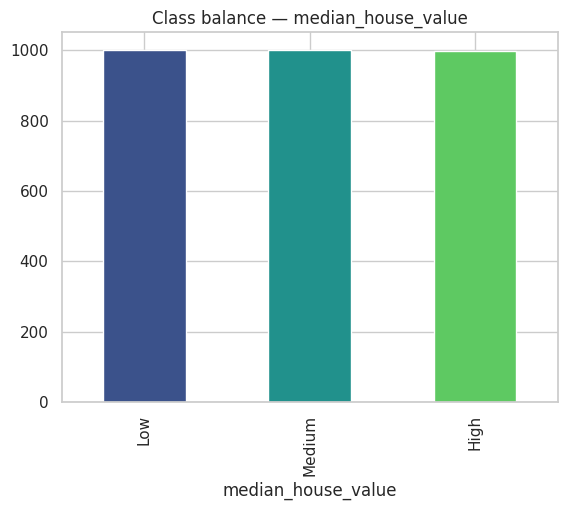

In [2]:
TARGET = None            # e.g. "Species"

df = df.dropna(axis=1, how="all").drop_duplicates()
TARGET = TARGET or df.columns[-1]
df = df.dropna(subset=[TARGET])
if len(df) > 20000: df = df.sample(20000, random_state=42)       # keep it fast

# 🧠 Innovation: numeric target with many values? Auto-convert to Low/Medium/High classes
if pd.api.types.is_numeric_dtype(df[TARGET]) and df[TARGET].nunique() > 15:
    df[TARGET] = pd.qcut(df[TARGET], 3, labels=["Low", "Medium", "High"], duplicates="drop")
    print("🪄 Continuous target → binned into Low / Medium / High")

y = df[TARGET].astype(str)
X = df.drop(columns=[TARGET])
# drop ID-like and super-high-cardinality text columns
X = X.drop(columns=[c for c in X if (X[c].nunique() == len(X) and X[c].dtype != "float64") or (X[c].dtype == "object" and X[c].nunique() > 50)])

print(f"🎯 Target: {TARGET} | Classes: {y.nunique()} | Features: {X.shape[1]}")
y.value_counts().plot.bar(title=f"Class balance — {TARGET}", color=sns.color_palette("viridis", y.nunique()))
plt.show()

## 3️⃣ The Algorithm Battle ⚔️
Every model gets the same smart preprocessing (imputing, scaling, encoding) in one pipeline.

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer, make_column_selector as sel
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import accuracy_score, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier

prep = make_column_transformer(
    (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), sel(dtype_include="number")),
    (make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), sel(dtype_exclude="number")))

base = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "SVM": SVC(probability=True, random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)}
base["🏆 Dream Team (Voting)"] = VotingClassifier([(k, v) for k, v in base.items() if k in ("Logistic Regression", "SVM", "Random Forest")], voting="soft")

strat = y if y.value_counts().min() > 1 else None
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42, stratify=strat)

rows, fitted = [], {}
for name, m in base.items():
    pipe = make_pipeline(prep, m); t = time.time()
    cv = cross_val_score(pipe, Xtr, ytr, cv=min(5, ytr.value_counts().min()) if ytr.value_counts().min() > 1 else 2).mean()
    pipe.fit(Xtr, ytr); p = pipe.predict(Xte); fitted[name] = pipe
    rows.append({"Algorithm": name, "CV Acc %": cv * 100, "Test Acc %": accuracy_score(yte, p) * 100,
                 "F1 (macro) %": f1_score(yte, p, average="macro") * 100, "Time (s)": time.time() - t})
    print(f"✔ {name:<24} {rows[-1]['Test Acc %']:.2f}%")

board = pd.DataFrame(rows).sort_values("Test Acc %", ascending=False).reset_index(drop=True)
board.index += 1
board.style.format("{:.2f}", subset=board.columns[1:]).background_gradient(cmap="viridis", subset=["CV Acc %", "Test Acc %", "F1 (macro) %"])

## 4️⃣ Leaderboard & Winner

In [ ]:
best = board.iloc[0]["Algorithm"]
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=board, y="Algorithm", x="Test Acc %", ax=ax[0], palette="viridis")
ax[0].set_title("Test Accuracy"); ax[0].set_xlim(max(0, board["Test Acc %"].min() - 10), 100)
sns.barplot(data=board, y="Algorithm", x="Time (s)", ax=ax[1], palette="rocket"); ax[1].set_title("Training Time")
plt.tight_layout(); plt.show()
print(f"🥇 WINNER: {best} with {board.iloc[0]['Test Acc %']:.2f}% accuracy")

## 5️⃣ Insights on the winner — confusion matrix + what matters most

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.inspection import permutation_importance

model = fitted[best]; pred = model.predict(Xte)
print(classification_report(yte, pred))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ConfusionMatrixDisplay.from_predictions(yte, pred, cmap="viridis", ax=ax[0], colorbar=False); ax[0].set_title(f"Confusion Matrix — {best}")

# 🧠 Innovation: model-agnostic feature importance (works for ANY winner)
imp = permutation_importance(model, Xte, yte, n_repeats=5, random_state=42)
imp = pd.Series(imp.importances_mean, index=X.columns).sort_values().tail(10)
imp.plot.barh(ax=ax[1], color="teal", title="Top features driving predictions")
plt.tight_layout(); plt.show()

## 6️⃣ Save the model & predict on a NEW file 🔮

In [ ]:
joblib.dump(model, "best_model.pkl")

try:
    print("📂 Upload a new file with the same columns (without target is fine):")
    new = load(list(files.upload())[0])
    out = new.reindex(columns=X.columns)
    new["Predicted_" + TARGET] = model.predict(out)
    new.to_csv("predictions.csv", index=False); files.download("predictions.csv")
    display(new.head())
except Exception as e:
    print("Skipped:", e)